In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import os

In [4]:
import tensorflow as tf

print("Num GPUs Available:", len(tf.config.experimental.list_physical_devices('GPU')))
print("GPU Details:", tf.config.experimental.list_physical_devices('GPU'))

Num GPUs Available: 1
GPU Details: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [5]:
# path = "../data"

# calendar = pd.read_csv(os.path.join(path, "calendar.csv"))
# selling_prices = pd.read_csv(os.path.join(path, "sell_prices.csv"))
# # sample_submission = pd.read_csv(os.path.join(path, "sample_submission.csv"))
# sales = pd.read_csv(os.path.join(path, "sales_train_evaluation.csv"))

In [6]:
# print(round(calendar.memory_usage(deep=True).sum()/(1024**2),2))
# print(round(selling_prices.memory_usage(deep=True).sum()/(1024**2),2))
# print(round(sales.memory_usage(deep=True).sum()/(1024**2),2))

In [7]:
# disater = pd.read_csv(os.path.join(path, "us_disasters_m5.csv")).head(500)
# disater.head(5)

In [8]:
# from sklearn.preprocessing import OrdinalEncoder

# def prep_calendar(df):
#     df = df.drop(["date", "weekday", "event_type_1", "event_type_2"], axis=1)
#     df = df.assign(d = df.d.str[2:].astype(int))
#     to_ordinal = ["event_name_1", "event_name_2"] 
#     df[to_ordinal] = df[to_ordinal].fillna("1")
#     df[to_ordinal] = OrdinalEncoder(dtype="int").fit_transform(df[to_ordinal]) + 1
#     to_int8 = ["wday", "month", "snap_CA", "snap_TX", "snap_WI"] + to_ordinal
#     df[to_int8] = df[to_int8].astype("int8")
    
#     return df

# # calendar = prep_calendar(calendar)
# # calendar.head()

In [9]:
# def downcast(df):
#     cols = df.dtypes.index.tolist()
#     types = df.dtypes.values.tolist()
    
#     for i, t in enumerate(types):
#         col = cols[i]
#         if 'int' in str(t):
#             c_min = df[col].min()
#             c_max = df[col].max()
#             if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
#                 df[col] = df[col].astype(np.int8)
#             elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
#                 df[col] = df[col].astype(np.int16)
#             elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
#                 df[col] = df[col].astype(np.int32)
#             else:
#                 df[col] = df[col].astype(np.int64)

#         elif 'float' in str(t):
#             c_min = df[col].min()
#             c_max = df[col].max()
#             # ⚠️ Không dùng float16 vì không lưu được trong Parquet
#             if c_min > np.finfo(np.float32).min and c_max < np.finfo(np.float32).max:
#                 df[col] = df[col].astype(np.float32)
#             else:
#                 df[col] = df[col].astype(np.float64)

#         elif str(t) == 'object':
#             if col == 'date':
#                 df[col] = pd.to_datetime(df[col], format='%Y-%m-%d')
#             else:
#                 df[col] = df[col].astype('category')
    
#     return df

In [10]:
# # Calculate memory usage before running the function
# memory_before = {
#     'calendar': calendar.memory_usage(deep=True).sum(),
#     'sales': sales.memory_usage(deep=True).sum(),
#     'prices': selling_prices.memory_usage(deep=True).sum()
# }

# sales = downcast(sales)
# prices = downcast(selling_prices)
# calendar = downcast(calendar)

# memory_after = {
#     'calendar': calendar.memory_usage(deep=True).sum(),
#     'sales': sales.memory_usage(deep=True).sum(),
#     'prices': prices.memory_usage(deep=True).sum()
# }

In [11]:
# def plot_memory_comparison(memory_before, memory_after):
#     """
#     Vẽ biểu đồ so sánh bộ nhớ sử dụng trước và sau khi tối ưu hóa.
    
#     Parameters:
#     -----------
#     memory_before : dict
#         Dictionary chứa bộ nhớ sử dụng trước khi tối ưu hóa.
#     memory_after : dict
#         Dictionary chứa bộ nhớ sử dụng sau khi tối ưu hóa.
#     """
#     import matplotlib.pyplot as plt
#     import numpy as np
    
#     # Lấy tên của các DataFrame
#     df_names = list(memory_before.keys())
    
#     # Tính toán giá trị bộ nhớ ở MB
#     before_mb = [memory_before[name] / (1024 * 1024) for name in df_names]
#     after_mb = [memory_after[name] / (1024 * 1024) for name in df_names]
    
#     # Tính phần trăm giảm bộ nhớ
#     reduction_pct = [(memory_before[name] - memory_after[name]) / memory_before[name] * 100 for name in df_names]
    
#     # Thiết lập vị trí của các cột
#     x = np.arange(len(df_names))
#     width = 0.35
    
#     # Tạo biểu đồ
#     fig, ax = plt.subplots(figsize=(12, 7))
    
#     # Vẽ cột
#     rects1 = ax.bar(x - width/2, before_mb, width, label='Trước khi downcast', color='#5DA5DA')
#     rects2 = ax.bar(x + width/2, after_mb, width, label='Sau khi downcast', color='#60BD68')
    
#     # Thêm nhãn, tiêu đề và các thông tin khác
#     ax.set_xlabel('DataFrame', fontsize=12)
#     ax.set_ylabel('Bộ nhớ sử dụng (MB)', fontsize=12)
#     ax.set_title('So sánh bộ nhớ sử dụng trước và sau khi áp dụng downcast', fontsize=14)
#     ax.set_xticks(x)
#     ax.set_xticklabels(df_names)
#     ax.legend()
    
#     # Thêm giá trị lên mỗi cột
#     def add_labels(rects):
#         for rect in rects:
#             height = rect.get_height()
#             ax.annotate(f'{height:.2f} MB',
#                          xy=(rect.get_x() + rect.get_width() / 2, height),
#                          xytext=(0, 3),  # 3 points vertical offset
#                          textcoords="offset points",
#                          ha='center', va='bottom')
    
#     add_labels(rects1)
#     add_labels(rects2)
    
#     # Thêm phần trăm giảm bộ nhớ
#     for i, pct in enumerate(reduction_pct):
#         ax.annotate(f'↓ {pct:.1f}%',
#                     xy=(x[i], min(before_mb[i], after_mb[i]) / 2),
#                     xytext=(0, 0),
#                     textcoords="offset points",
#                     ha='center', va='center',
#                     color='darkred',
#                     fontweight='bold',
#                     bbox=dict(boxstyle="round,pad=0.3", fc="lightyellow", ec="gold", alpha=0.8))
    
#     plt.tight_layout()
    
#     # Thêm biểu đồ tổng hợp
#     ax2 = fig.add_axes([0.15, 0.15, 0.25, 0.25])
#     total_before = sum(before_mb)
#     total_after = sum(after_mb)
#     total_reduction = (total_before - total_after) / total_before * 100
    
#     ax2.bar(['Trước', 'Sau'], [total_before, total_after], color=['#5DA5DA', '#60BD68'])
#     ax2.set_title('Tổng bộ nhớ', fontsize=10)
#     ax2.set_ylabel('MB', fontsize=8)
#     ax2.annotate(f'↓ {total_reduction:.1f}%', 
#                 xy=(0.5, min(total_before, total_after) / 2),
#                 xytext=(0, 0),
#                 textcoords="offset points",
#                 ha='center', va='center',
#                 color='darkred',
#                 fontweight='bold',
#                 bbox=dict(boxstyle="round,pad=0.3", fc="lightyellow", ec="gold", alpha=0.8))
    
#     plt.show()
    
#     # In thông tin chi tiết
#     print("\nThông tin chi tiết về bộ nhớ sử dụng:")
#     print(f"{'DataFrame':<10} {'Trước (MB)':<15} {'Sau (MB)':<15} {'Giảm (MB)':<15} {'Giảm (%)':<10}")
#     print("-" * 70)
    
#     for i, name in enumerate(df_names):
#         reduced = memory_before[name] - memory_after[name]
#         reduced_mb = reduced / (1024 * 1024)
#         print(f"{name:<10} {before_mb[i]:<15.2f} {after_mb[i]:<15.2f} {reduced_mb:<15.2f} {reduction_pct[i]:<10.1f}")
    
#     print("-" * 70)
#     total_reduced_mb = (sum(memory_before.values()) - sum(memory_after.values())) / (1024 * 1024)
#     print(f"{'TỔNG':<10} {total_before:<15.2f} {total_after:<15.2f} {total_reduced_mb:<15.2f} {total_reduction:<10.1f}")

# # Sử dụng hàm
# plot_memory_comparison(memory_before, memory_after)

In [12]:
# calendar.to_parquet('done_cal.parquet')
# sales.to_parquet('done_sales.parquet')
# prices.to_parquet('done_prices.parquet')

In [13]:
# round(prices.memory_usage(deep=True).sum()/1024**2,2)

In [14]:
# prices.head(5)

In [15]:
# import gc
# del calendar
# gc.collect()

In [16]:
# sales = pd.read_parquet('done_sales.parquet')
# prices = pd.read_parquet('done_prices.parquet')
# calendar = pd.read_parquet('done_cal.parquet')
# sample_submission = pd.read_csv('../data/sample_submission.csv')

In [17]:
# print(round(sales.memory_usage(deep=True).sum()/1024**2,2))
# print(round(prices.memory_usage(deep=True).sum()/1024**2,2))
# print(round(calendar.memory_usage(deep=True).sum()/1024**2,2))

In [18]:
# sample_submission.head(10)

In [19]:
# from sklearn.model_selection import train_test_split
# import lightgbm as lgb
# LAGS = [7, 28]
# WINDOWS = [7, 28]
# FIRST = 1942 # first to predict
# LENGTH = 28

# def demand_features(df):
#     """ Derive features from sales data and remove rows with missing values """
    
#     for lag in LAGS:
#         df[f'lag_t{lag}'] = df.groupby('id')['demand'].transform(lambda x: x.shift(lag)).astype("float32")
#         for w in WINDOWS:
#             df[f'rolling_mean_lag{lag}_w{w}'] = df.groupby('id')[f'lag_t{lag}'].transform(lambda x: x.rolling(w).mean()).astype("float32")
        
#     return df

# def demand_features_eval(df):
#     """ Same as demand_features but for the step-by-step evaluation """
#     out = df.groupby('id', sort=False).last()
#     for lag in LAGS:
#         out[f'lag_t{lag}'] = df.groupby('id', sort=False)['demand'].nth(-lag-1).astype("float32")
#         for w in WINDOWS:
#             out[f'rolling_mean_lag{lag}_w{w}'] = df.groupby('id', sort=False)['demand'].nth(list(range(-lag-w, -lag))).groupby('id', sort=False).mean().astype("float32")
    
#     return out.reset_index()

# def prep_data(df, drop_d=1000):
#     """ Prepare model data sets """
    
#     # Kick out old dates
#     df = df.drop(["d_" + str(i+1) for i in range(drop_d)], axis=1)

#     # Reshape to long
#     df = df.assign(id=df.id.str.replace("_evaluation", ""))
#     df = df.reindex(columns=df.columns.tolist() + ["d_" + str(FIRST + i) for i in range(LENGTH)])
#     df = df.melt(id_vars=["id", "item_id", "store_id", "state_id", "dept_id", "cat_id"], var_name='d', value_name='demand')
#     df = df.assign(d=df.d.str[2:].astype("int64"),
#                    demand=df.demand.astype("float32"))
    
#     # Add demand features
#     df = demand_features(df)
    
#     # Remove rows with NAs
#     df = df[df.d > (drop_d + max(LAGS) + max(WINDOWS))]
 
#     # Join calendar & prices
#     df = df.merge(calendar, how="left", on="d")
#     df = df.merge(prices, how="left", on=["store_id", "item_id", "wm_yr_wk"])
#     df = df.drop(["wm_yr_wk"], axis=1)
    
#     # Ordinal encoding of remaining categorical fields
#     for v in ["item_id", "store_id", "state_id", "dept_id", "cat_id"]:
#         df[v] = OrdinalEncoder(dtype="int").fit_transform(df[[v]]).astype("int16") + 1
    
#     # Determine list of covariables
#     x = list(set(df.columns) - {'id', 'd', 'demand'})
            
#     # Split into test, valid, train
#     test = df[df.d >= FIRST - max(LAGS) - max(WINDOWS) - 28]
#     df = df[df.d < FIRST]

#     xtrain, xvalid, ytrain, yvalid = train_test_split(df[x], df["demand"], test_size=0.1, shuffle=True, random_state=23520945)
#     train = lgb.Dataset(xtrain, label = ytrain)
#     valid = lgb.Dataset(xvalid, label = yvalid)

#     return train, valid, test, x

# def fit_model(train, valid):
#     """ Fit LightGBM model """
     
#     params = {
#         'metric': 'rmse',
#         'objective': 'poisson',
#         'seed': 200,
#         'force_row_wise' : True,
#         'learning_rate' : 0.08,
#         'lambda': 0.1,
#         'num_leaves': 63,
#         'sub_row' : 0.7,
#         'bagging_freq' : 1,
#         'colsample_bytree': 0.7
#     }

#     fit = lgb.train(params, 
#                     train, 
#                     num_boost_round = 2000, 
#                     valid_sets = [valid], 
#                     early_stopping_rounds = 200,
#                     verbose_eval = 100)
    
#     lgb.plot_importance(fit, importance_type="gain", precision=0, height=0.5, figsize=(6, 10));
    
#     return fit

# def pred_all(fit, test, x):
#     """ Calculate predictions """
    
#     # Recursive prediction
#     for i, day in enumerate(np.arange(FIRST, FIRST + LENGTH)):
#         test_day = demand_features_eval(test[(test.d <= day) & (test.d >= day - max(LAGS) - max(WINDOWS))])
#         test.loc[test.d == day, "demand"] = fit.predict(test_day[x])
    
#     return test

# # def pred_to_csv(test, cols=sample_submission.columns, file="submission.csv"):
# #     """ Reshape predictions and save submission csv """
     
# #     # Prepare for reshaping
# #     test = test.assign(id=test.id + "_" + np.where(test.d < FIRST, "validation", "evaluation"),
# #                        F="F" + (test.d - FIRST + LENGTH + 1 - LENGTH * (test.d >= FIRST)).astype("str"))
    
# #     # Reshape
# #     submission = test.pivot(index="id", columns="F", values="demand").reset_index()[cols].fillna(1)
    
# #     # Export
# #     submission.to_csv(file, index=False)
    
# #     return True

In [20]:
# import gc
# del sample_submission
# gc.collect()

In [ ]:
from sklearn.model_selection import train_test_split
import lightgbm as lgb
LAGS = [7, 28]
WINDOWS = [7, 28]
FIRST = 1942 # first to predict
LENGTH = 28

def demand_features(df):
    """ Derive features from sales data and remove rows with missing values """
    
    for lag in LAGS:
        df[f'lag_t{lag}'] = df.groupby('id')['demand'].transform(lambda x: x.shift(lag)).astype("float32")
        for w in WINDOWS:
            df[f'rolling_mean_lag{lag}_w{w}'] = df.groupby('id')[f'lag_t{lag}'].transform(lambda x: x.rolling(w).mean()).astype("float32")
        
    return df

def demand_features_eval(df):
    """ Same as demand_features but for the step-by-step evaluation """
    out = df.groupby('id', sort=False).last()
    for lag in LAGS:
        out[f'lag_t{lag}'] = df.groupby('id', sort=False)['demand'].nth(-lag-1).astype("float32")
        for w in WINDOWS:
            out[f'rolling_mean_lag{lag}_w{w}'] = df.groupby('id', sort=False)['demand'].nth(list(range(-lag-w, -lag))).groupby('id', sort=False).mean().astype("float32")
    
    return out.reset_index()

def prep_data(df, drop_d=1000):
    """ Prepare model data sets """
    
    # Kick out old dates
    df = df.drop(["d_" + str(i+1) for i in range(drop_d)], axis=1)

    # Reshape to long
    df = df.assign(id=df.id.str.replace("_evaluation", ""))
    df = df.reindex(columns=df.columns.tolist() + ["d_" + str(FIRST + i) for i in range(LENGTH)])
    df = df.melt(id_vars=["id", "item_id", "store_id", "state_id", "dept_id", "cat_id"], var_name='d', value_name='demand')
    df = df.assign(d=df.d.str[2:].astype("int64"),
                   demand=df.demand.astype("float32"))
    
    # Add demand features
    df = demand_features(df)
    
    # Remove rows with NAs
    df = df[df.d > (drop_d + max(LAGS) + max(WINDOWS))]
 
    # Join calendar & prices
    df = df.merge(calendar, how="left", on="d")
    df = df.merge(prices, how="left", on=["store_id", "item_id", "wm_yr_wk"])
    df = df.drop(["wm_yr_wk"], axis=1)
    
    # Ordinal encoding of remaining categorical fields
    for v in ["item_id", "store_id", "state_id", "dept_id", "cat_id"]:
        df[v] = OrdinalEncoder(dtype="int").fit_transform(df[[v]]).astype("int16") + 1
    
    # Determine list of covariables
    x = list(set(df.columns) - {'id', 'd', 'demand'})
            
    # Split into test, valid, train
    test = df[df.d >= FIRST - max(LAGS) - max(WINDOWS) - 28]
    df = df[df.d < FIRST]

    return df, test, x

In [22]:
# df, test, x = prep_data(sales, 1000 - 28)

In [23]:
# print(round(df.memory_usage(deep=True).sum()/1024**2,2))

In [24]:
# print(test.head(5))
# print(round(test.memory_usage(deep=True).sum()/1024**2,2))

In [25]:
# df.to_parquet('../data/train_val.parquet')
# test.to_parquet('../data/test.parquet')

In [26]:
# df['state_id'].unique()

In [27]:
# import gc
# del calendar, prices, sales, df
# gc.collect()

In [28]:
# import gc

# # Force garbage collection
# gc.collect()

# import os
# os.environ["CUDA_VISIBLE_DEVICES"] = "0"  # Chỉ dùng GPU số 0

# train, valid, test, x = prep_data(sales, 1000 - 28)
# fit = fit_model(train, valid)
# pred = pred_all(fit, test, x)
# # pred_to_csv(pred, cols=sample_submission.columns, file="submission.csv")

In [29]:
# import gc
# del df
# gc.collect

In [30]:
# # not_disater = pd.read_csv('../data/us_disaster_declarations.csv')
# disater = pd.read_csv('../data/us_disasters_m5.csv')

In [31]:
# disater

In [32]:
# disater.columns

In [33]:
# disater['declaration_date'][:10]

In [34]:
# def prep_disater(disater):
#     done_dis = disater[['state', 'incident_type', 'incident_begin_date', 'incident_end_date']].copy()
    
#     # Chuyển đổi kiểu datetime
#     done_dis['incident_begin_date'] = pd.to_datetime(done_dis['incident_begin_date'], errors='coerce')
#     done_dis['incident_end_date'] = pd.to_datetime(done_dis['incident_end_date'], errors='coerce')
    
#     # Thay thế giá trị thiếu trong incident_end_date
#     done_dis['incident_end_date'] = done_dis['incident_end_date'].fillna(
#         done_dis['incident_begin_date'] + pd.Timedelta(days=1)
#     )
    
#     return done_dis

# done_dis = prep_disater(disater)
# done_dis

In [35]:
# done_dis.to_parquet('../data/done_dis.parquet')

In [36]:
# import gc 
# del df
# gc.collect()

In [37]:
# calendar = pd.read_parquet('done_cal.parquet')
# calendar
# prices = pd.read_parquet('done_prices.parquet')
# prices
# sales = pd.read_parquet('done_sales.parquet')
# sales

In [38]:
# done_dis = pd.read_parquet('../data/done_dis.parquet')
# done_dis
# done_dis['incident_type'].unique()
# done_dis['state'].unique()
# # B1: Gắn tên bang từ state_id để khớp done_dis
# state_map = {
#     'CA': '1',
#     'TX': '2',
#     'WI': '3'
# }
# done_dis['state'] = done_dis['state'].map(state_map)
# done_dis['incident_begin_date'] = done_dis['incident_begin_date'].dt.tz_localize(None)
# done_dis['incident_end_date'] = done_dis['incident_end_date'].dt.tz_localize(None)

In [39]:
# from sklearn.preprocessing import OrdinalEncoder
# LAGS = [7, 28]
# WINDOWS = [7, 28]
# FIRST = 1942 # first to predict
# LENGTH = 28

# def demand_features(df):
#     """ Derive features from sales data and remove rows with missing values """
    
#     for lag in LAGS:
#         df[f'lag_t{lag}'] = df.groupby('id')['demand'].transform(lambda x: x.shift(lag)).astype("float32")
#         for w in WINDOWS:
#             df[f'rolling_mean_lag{lag}_w{w}'] = df.groupby('id')[f'lag_t{lag}'].transform(lambda x: x.rolling(w).mean()).astype("float32")
        
#     return df

# def prep_data(df, drop_d=1000):
#     """ Prepare model data sets """
    
#     # Kick out old dates
#     df = df.drop(["d_" + str(i+1) for i in range(drop_d)], axis=1)

#     # Reshape to long
#     df = df.assign(id=df.id.str.replace("_evaluation", ""))
#     df = df.reindex(columns=df.columns.tolist() + ["d_" + str(FIRST + i) for i in range(LENGTH)])
#     df = df.melt(id_vars=["id", "item_id", "store_id", "state_id", "dept_id", "cat_id"], var_name='d', value_name='demand')
#     df = df.assign(d=df.d.str[2:].astype("int64"),
#                    demand=df.demand.astype("float32"))
    
#     # Add demand features
#     df = demand_features(df)
    
#     # Remove rows with NAs
#     df = df[df.d > (drop_d + max(LAGS) + max(WINDOWS))]
 
#     # Join calendar & prices
#     df = df.merge(calendar, how="left", on="d")
#     df = df.merge(prices, how="left", on=["store_id", "item_id", "wm_yr_wk"])
#     df = df.drop(["wm_yr_wk"], axis=1)
    
#     # Ordinal encoding of remaining categorical fields
#     for v in ["item_id", "store_id","dept_id", "cat_id"]:
#         df[v] = OrdinalEncoder(dtype="int").fit_transform(df[[v]]).astype("int16") + 1
    
#     # Determine list of covariables
#     x = list(set(df.columns) - {'id', 'd', 'demand'})

#     df['wday'].unique()
#     df['state_id'].unique()
#     df['state_id'] = df['state_id'].map(state_map)
#     df['state_id'].unique()
#     df['date']
#     print(df['date'].dtype)
#     print(done_dis['incident_begin_date'])
                
#     # B3: Khởi tạo cột disaster_type (ban đầu là None)
#     df['disaster_type'] = None

#     # B4: Gắn loại thảm họa cho các ngày bị ảnh hưởng
#     for _, row in done_dis.iterrows():
#         mask = (
#             (df['state_id'] == row['state']) &
#             (df['date'] >= row['incident_begin_date']) &
#             (df['date'] <= row['incident_end_date'])
#         )
#         df.loc[mask, 'disaster_type'] = row['incident_type']

#     # B5: Tính tổng doanh thu theo loại thảm họa
#     revenue_by_disaster = df[df['disaster_type'].notna()].groupby('disaster_type')['demand'].sum()

#     # B6: Chuẩn hóa giá trị doanh thu để gán severity flag
#     # Giả sử: doanh thu càng thấp => mức độ ảnh hưởng càng nặng
#     rank = revenue_by_disaster.rank(ascending=True, method='min')  # nhỏ nhất = 1
#     max_rank = rank.max()
#     severity_map = (rank / max_rank * 5).astype(int)  # chia thành 1–5

#     # B7: Gán cột flag theo loại thảm họa
#     df['disaster_severity_flag'] = df['disaster_type'].map(severity_map)
#     df['disaster_severity_flag'] = df['disaster_severity_flag'].fillna(0).astype(int)  # nếu không bị thiên tai thì là 0

#     return df, x

# df, x = prep_data(sales, 1000 - 28)
# print(round(df.memory_usage(deep=True).sum()/1024**2,2))
# print(x)

In [40]:
#Downcast in order to save memory
def downcast(df):
    cols = df.dtypes.index.tolist()
    types = df.dtypes.values.tolist()
    for i,t in enumerate(types):
        if 'int' in str(t):
            if df[cols[i]].min() > np.iinfo(np.int8).min and df[cols[i]].max() < np.iinfo(np.int8).max:
                df[cols[i]] = df[cols[i]].astype(np.int8)
            elif df[cols[i]].min() > np.iinfo(np.int16).min and df[cols[i]].max() < np.iinfo(np.int16).max:
                df[cols[i]] = df[cols[i]].astype(np.int16)
            elif df[cols[i]].min() > np.iinfo(np.int32).min and df[cols[i]].max() < np.iinfo(np.int32).max:
                df[cols[i]] = df[cols[i]].astype(np.int32)
            else:
                df[cols[i]] = df[cols[i]].astype(np.int64)
        elif 'float' in str(t):
            if df[cols[i]].min() > np.finfo(np.float32).min and df[cols[i]].max() < np.finfo(np.float32).max:
                df[cols[i]] = df[cols[i]].astype(np.float32)
            else:
                df[cols[i]] = df[cols[i]].astype(np.float64)
        # elif str(t) == 'object':
        #     if cols[i] == 'date':
        #         df[cols[i]] = pd.to_datetime(df[cols[i]], format='%Y-%m-%d')
        #     else:
        #         df[cols[i]] = df[cols[i]].astype('category')
    return df

In [41]:
# df = downcast(df)

In [42]:
# print(f'{round(prices.memory_usage(deep=True).sum()/1024**2)} MB')

In [43]:
# df.to_parquet('../data/train_val.parquet')

In [44]:
# import gc
# del prices, sales, calendar, df, done_dis
# gc.collect()

In [45]:
# df = pd.read_parquet('../data/train_val.parquet')
# df['wday'].unique()
# df['state_id'].unique()
# df['state_id'] = df['state_id'].map(state_map)
# df['state_id'].unique()
# df['date']
# print(df['date'].dtype)
# print(done_dis['incident_begin_date'])

In [46]:
# # B3: Khởi tạo cột disaster_type (ban đầu là None)
# df['disaster_type'] = None

# # B4: Gắn loại thảm họa cho các ngày bị ảnh hưởng
# for _, row in done_dis.iterrows():
#     mask = (
#         (df['state_id'] == row['state']) &
#         (df['date'] >= row['incident_begin_date']) &
#         (df['date'] <= row['incident_end_date'])
#     )
#     df.loc[mask, 'disaster_type'] = row['incident_type']


In [47]:
# df['disaster_type'].unique()

In [48]:
# # B5: Tính tổng doanh thu theo loại thảm họa
# revenue_by_disaster = df[df['disaster_type'].notna()].groupby('disaster_type')['demand'].sum()

# # B6: Chuẩn hóa giá trị doanh thu để gán severity flag
# # Giả sử: doanh thu càng thấp => mức độ ảnh hưởng càng nặng
# rank = revenue_by_disaster.rank(ascending=True, method='min')  # nhỏ nhất = 1
# max_rank = rank.max()
# severity_map = (rank / max_rank * 5).astype(int)  # chia thành 1–5

# # B7: Gán cột flag theo loại thảm họa
# df['disaster_severity_flag'] = df['disaster_type'].map(severity_map)
# df['disaster_severity_flag'] = df['disaster_severity_flag'].fillna(0).astype(int)  # nếu không bị thiên tai thì là 0


In [49]:
# df['disaster_severity_flag'].unique()

In [50]:
# round(df.memory_usage(deep=True).sum()/1024**2,2)

In [51]:
# df.to_parquet('../data/train_val.parquet')

In [52]:
# import gc
# del train, valid, sample_submission
# gc.collect()

In [53]:
train = pd.read_parquet('../data/train_val.parquet')
len(train.columns)

24

In [54]:
train['disaster_severity_flag'].unique()

array([ 0, 15,  3,  7, 11], dtype=int8)

In [55]:
print(round(train.memory_usage(deep=True).sum()/1024**2))

1645


In [56]:
# train = downcast(train)
# print(round(train.memory_usage(deep=True).sum()/1024**2))

In [57]:
# train.to_parquet('../data/train_val.parquet')

In [58]:
sample_submission = pd.read_csv('../data/sample_submission.csv')
sample_submission = downcast(sample_submission)

In [59]:
from sklearn.model_selection import train_test_split
import lightgbm as lgb

LAGS = [7, 28]
WINDOWS = [7, 28]
FIRST = 1942 # first to predict
LENGTH = 28

def demand_features_eval(df):
    """ Same as demand_features but for the step-by-step evaluation """
    out = df.groupby('id', sort=False).last()
    for lag in LAGS:
        out[f'lag_t{lag}'] = df.groupby('id', sort=False)['demand'].nth(-lag-1).astype("float32")
        for w in WINDOWS:
            out[f'rolling_mean_lag{lag}_w{w}'] = df.groupby('id', sort=False)['demand'].nth(list(range(-lag-w, -lag))).groupby('id', sort=False).mean().astype("float32")
    
    return out.reset_index()

def prep_train(df,drop_d = 1000):
    
    x = list(set(df.columns) - {'id', 'd', 'demand'})
    print(x)
    # Split into test, valid, train
    test = df[df.d >= FIRST - max(LAGS) - max(WINDOWS) - 28]
    df = df[df.d < FIRST]

    xtrain, xvalid, ytrain, yvalid = train_test_split(df[x], df["demand"], test_size=0.1, shuffle=True, random_state=54)
    train = lgb.Dataset(xtrain, label = ytrain)
    valid = lgb.Dataset(xvalid, label = yvalid)
    return train, valid, test, x

In [60]:
import gc

# Force garbage collection
gc.collect()

33

In [61]:
train, valid, test, x = prep_train(train, 1000 - 28)

['year', 'event_name_2', 'snap_WI', 'state_id', 'rolling_mean_lag28_w28', 'snap_CA', 'cat_id', 'month', 'store_id', 'item_id', 'rolling_mean_lag7_w28', 'rolling_mean_lag28_w7', 'event_name_1', 'lag_t28', 'wday', 'sell_price', 'snap_TX', 'dept_id', 'rolling_mean_lag7_w7', 'disaster_severity_flag', 'lag_t7']


In [62]:
def fit_model(train, valid):
    """ Fit LightGBM model """
     
    params = {
        'metric': 'rmse',
        'objective': 'poisson',
        'seed': 200,
        'force_row_wise' : True,
        'learning_rate' : 0.08,
        'lambda': 0.1,
        'num_leaves': 63,
        'sub_row' : 0.7,
        'bagging_freq' : 1,
        'colsample_bytree': 0.7
    }

    fit = lgb.train(params, 
                    train, 
                    num_boost_round = 2000, 
                    valid_sets = [valid], 
                    early_stopping_rounds = 200,
                    verbose_eval = 100)
    
    lgb.plot_importance(fit, importance_type="gain", precision=0, height=0.5, figsize=(6, 10));
    
    return fit


def pred_all(fit, test, x):
    """ Calculate predictions """
    
    # Recursive prediction
    for i, day in enumerate(np.arange(FIRST, FIRST + LENGTH)):
        test_day = demand_features_eval(test[(test.d <= day) & (test.d >= day - max(LAGS) - max(WINDOWS))])
        test.loc[test.d == day, "demand"] = fit.predict(test_day[x])
    
    return test

def pred_to_csv(test, cols=sample_submission.columns, file="submission.csv"):
    """ Reshape predictions and save submission csv """
     
    # Prepare for reshaping
    test = test.assign(id=test.id + "_" + np.where(test.d < FIRST, "validation", "evaluation"),
                       F="F" + (test.d - FIRST + LENGTH + 1 - LENGTH * (test.d >= FIRST)).astype("str"))
    
    # Reshape
    submission = test.pivot(index="id", columns="F", values="demand").reset_index()[cols].fillna(1)
    
    # Export
    submission.to_csv(file, index=False)
    
    return True

c:\Users\Admin\anaconda3\envs\GPU\lib\site-packages\lightgbm\engine.py:181: UserWarning: 'early_stopping_rounds' argument is deprecated and will be removed in a future release of LightGBM. Pass 'early_stopping()' callback via 'callbacks' argument instead.
  _log_warning("'early_stopping_rounds' argument is deprecated and will be removed in a future release of LightGBM. "
c:\Users\Admin\anaconda3\envs\GPU\lib\site-packages\lightgbm\engine.py:239: UserWarning: 'verbose_eval' argument is deprecated and will be removed in a future release of LightGBM. Pass 'log_evaluation()' callback via 'callbacks' argument instead.
  _log_warning("'verbose_eval' argument is deprecated and will be removed in a future release of LightGBM. "


[LightGBM] [Info] Total Bins 1788
[LightGBM] [Info] Number of data points in the train set: 25053633, number of used features: 21


c:\Users\Admin\anaconda3\envs\GPU\lib\site-packages\lightgbm\basic.py:1780: UserWarning: Overriding the parameters from Reference Dataset.
  _log_warning('Overriding the parameters from Reference Dataset.')
c:\Users\Admin\anaconda3\envs\GPU\lib\site-packages\lightgbm\basic.py:1513: UserWarning: categorical_column in param dict is overridden.
  _log_warning(f'{cat_alias} in param dict is overridden.')


[LightGBM] [Info] Start training from score 0.206062
Training until validation scores don't improve for 200 rounds
[100]	valid_0's rmse: 2.25091
[200]	valid_0's rmse: 2.22023
[300]	valid_0's rmse: 2.19941
[400]	valid_0's rmse: 2.1859
[500]	valid_0's rmse: 2.17583
[600]	valid_0's rmse: 2.16855
[700]	valid_0's rmse: 2.16197
[800]	valid_0's rmse: 2.1567
[900]	valid_0's rmse: 2.1522
[1000]	valid_0's rmse: 2.14773
[1100]	valid_0's rmse: 2.14442
[1200]	valid_0's rmse: 2.14182
[1300]	valid_0's rmse: 2.13848
[1400]	valid_0's rmse: 2.13617
[1500]	valid_0's rmse: 2.1339
[1600]	valid_0's rmse: 2.13129
[1700]	valid_0's rmse: 2.12935
[1800]	valid_0's rmse: 2.12761
[1900]	valid_0's rmse: 2.12548
[2000]	valid_0's rmse: 2.12363
Did not meet early stopping. Best iteration is:
[1999]	valid_0's rmse: 2.12363


ValueError: cannot reindex from a duplicate axis

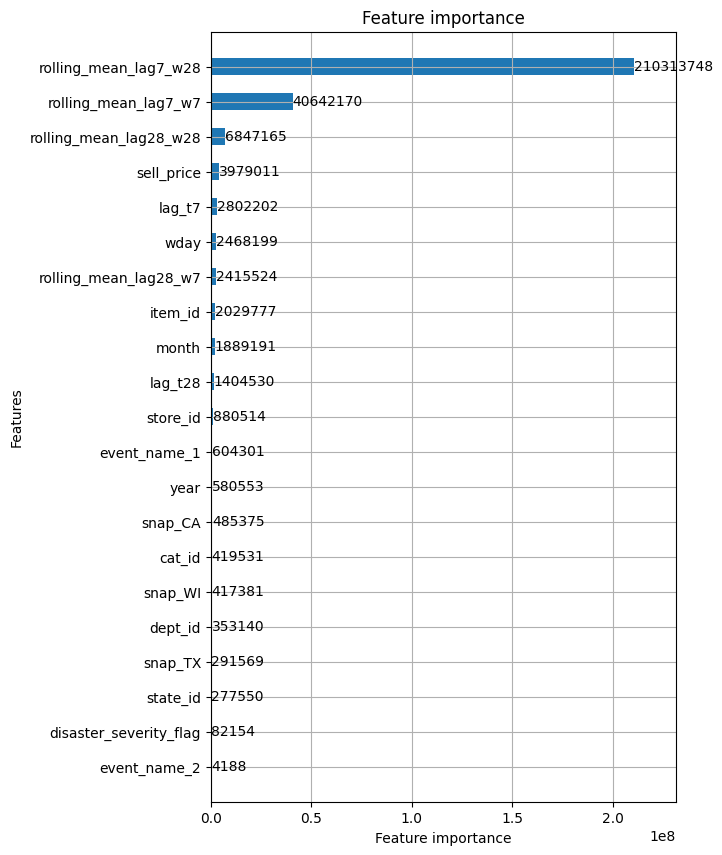

In [63]:
fit = fit_model(train, valid)
pred = pred_all(fit, test, x)
pred_to_csv(pred, cols=sample_submission.columns, file="submission.csv")

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import gc

In [2]:
gold  = pd.read_csv('../data/gold_data.csv')
print(gold.columns)
gold

Index(['Date', 'Price', 'Open', 'High', 'Low', 'Vol.', 'Change %'], dtype='object')


,Date,Price,Open,High,Low,Vol.,Change %
0,06/17/2016,"1,294.80","1,282.40","1,302.70","1,278.80",211.62K,-0.28%
1,06/16/2016,"1,298.40","1,295.00","1,318.90","1,280.10",354.15K,0.78%
2,06/15/2016,"1,288.30","1,288.10","1,300.00","1,281.30",199.45K,0.02%
3,06/14/2016,"1,288.10","1,286.20","1,293.00","1,278.60",193.07K,0.09%
4,06/13/2016,"1,286.90","1,278.30","1,290.30","1,275.20",202.81K,0.86%
...,...,...,...,...,...,...,...
1352,02/04/2011,"1,349.00","1,356.40","1,361.00","1,345.50",141.18K,-0.30%
1353,02/03/2011,"1,353.00","1,336.00","1,356.60","1,325.40",189.23K,1.57%
1354,02/02/2011,"1,332.10","1,343.50","1,345.60","1,327.30",109.74K,-0.61%
1355,02/01/2011,"1,340.30","1,334.00","1,344.10","1,326.00",146.59K,0.43%


In [5]:
gold['Date']
# Giả sử df là DataFrame chứa cột Date
gold['Date'] = pd.to_datetime(gold['Date'], format='%m/%d/%Y')
gold['Date']

0      2016-06-17
1      2016-06-16
2      2016-06-15
3      2016-06-14
4      2016-06-13
          ...    
1352   2011-02-04
1353   2011-02-03
1354   2011-02-02
1355   2011-02-01
1356   2011-01-31
Name: Date, Length: 1357, dtype: datetime64[ns]

In [31]:
done_gold = gold[['Date','Price']]
done_gold = done_gold.sort_values(by='Date')
done_gold.to_parquet('../data/done_gold.parquet',index=False)


In [8]:
ufc = pd.read_csv('../data/ufc.csv')
print(ufc.columns)
ufc.head(5)

Index(['event_id', 'event_name', 'event_date', 'event_city', 'event_state',
       'event_country', 'event_url'],
      dtype='object')


,event_id,event_name,event_date,event_city,event_state,event_country,event_url
0,665,UFC Fight Night: Dawson vs. Green,2023-10-07,Las Vegas,Nevada,USA,http://ufcstats.com/event-details/c8a49ff2acb6...
1,664,UFC Fight Night: Fiziev vs. Gamrot,2023-09-23,Las Vegas,Nevada,USA,http://ufcstats.com/event-details/c945adc22c2b...
2,663,UFC Fight Night: Grasso vs. Shevchenko 2,2023-09-16,Las Vegas,Nevada,USA,http://ufcstats.com/event-details/8fa2b0657236...
3,662,UFC 293: Adesanya vs. Strickland,2023-09-09,Sydney,New South Wales,Australia,http://ufcstats.com/event-details/ece280745f87...
4,661,UFC Fight Night: Gane vs. Spivac,2023-09-02,Paris,Ile-de-France,France,http://ufcstats.com/event-details/ef61d9f5176b...


In [18]:
df_usa = ufc[
    (ufc['event_country'] == 'USA') &
    (ufc['event_state'].isin({'Texas', 'California', 'Wisconsin'}))
]
print(len(df_usa['event_date']))
print(df_usa.columns)

59
Index(['event_id', 'event_name', 'event_date', 'event_city', 'event_state',
       'event_country', 'event_url'],
      dtype='object')


In [26]:
done_ufc = df_usa[['event_date','event_state']]

In [27]:
done_ufc = done_ufc.sort_values(by='event_date')


In [28]:
done_ufc.to_parquet('../data/done_ufc.parquet',index=False)

In [29]:
kii = pd.read_parquet('../data/done_ufc.parquet')
kii.head(5)

,event_date,event_state
0,2006-04-15,California
1,2006-05-27,California
2,2006-09-23,California
3,2006-11-18,California
4,2006-12-13,California
